In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

In [74]:
df = pd.read_csv("day.csv")

In [75]:
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values("dteday").reset_index(drop=True)

In [76]:
y = df.set_index("dteday")["cnt"].astype(float).asfreq("D")

In [77]:
print("Observations:", len(y))

Observations: 731


In [78]:
print("Missing time-series values:", y.isna().sum())

Missing time-series values: 0


In [79]:
print("Date range:", y.index.min(), "to", y.index.max())

Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00


In [ ]:
if y.isna().any():
    raise ValueError("Missing dates or demand values must be handled before modeling.")

In [81]:
y_ma7 = y.rolling(window=7).mean()

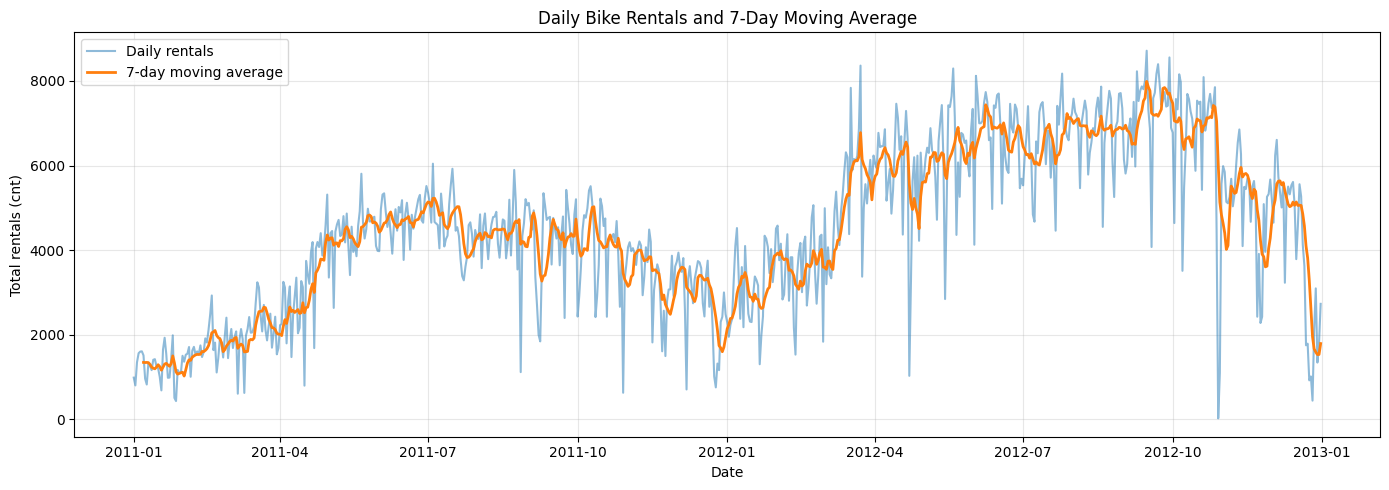

In [82]:
plt.figure(figsize=(14, 5))
plt.plot(y.index, y, label="Daily rentals", alpha=0.5)
plt.plot(y.index, y_ma7, label="7-day moving average", linewidth=2)

plt.title("Daily Bike Rentals and 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Total rentals (cnt)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

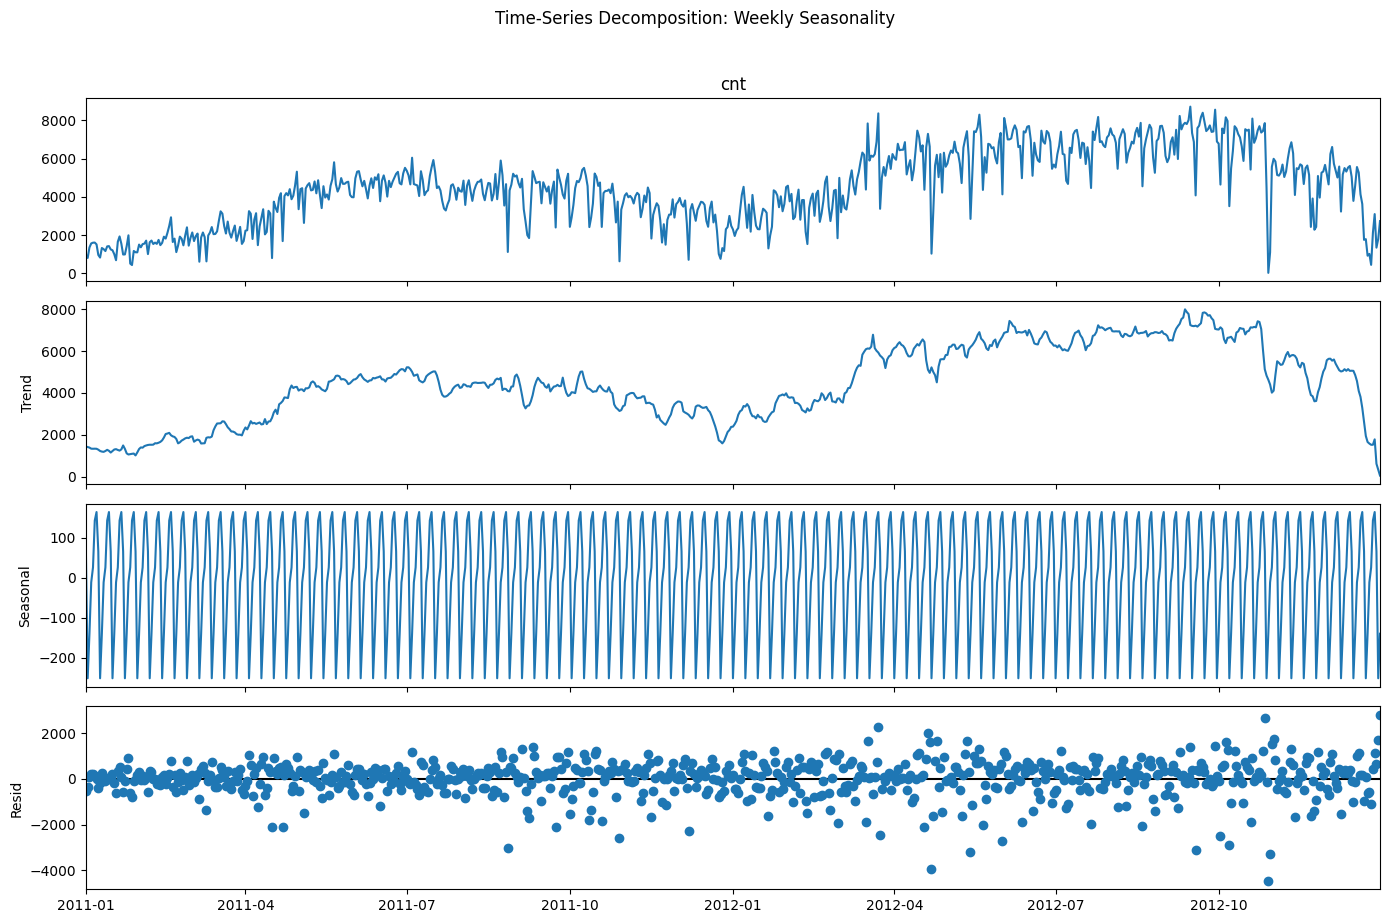

In [83]:
decomposition = seasonal_decompose(
    y,
    model="additive",
    period=7,
    extrapolate_trend="freq"
)

fig = decomposition.plot()
fig.set_size_inches(14, 9)
fig.suptitle("Time-Series Decomposition: Weekly Seasonality", y=1.02)
plt.tight_layout()
plt.show()

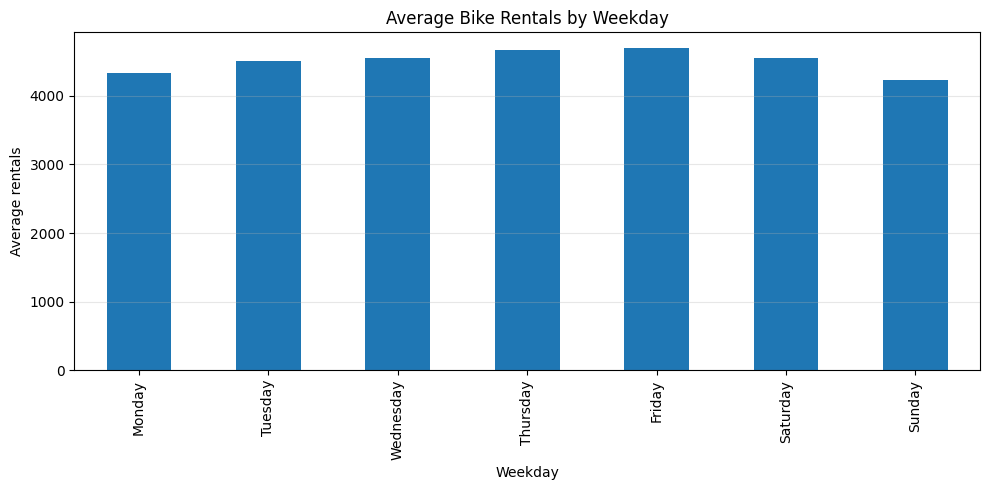

,cnt
weekday_name,
Monday,4338.12
Tuesday,4510.66
Wednesday,4548.54
Thursday,4667.26
Friday,4690.29
Saturday,4550.54
Sunday,4228.83


In [84]:
df["weekday_name"] = df["dteday"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_mean = (
    df.groupby("weekday_name")["cnt"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_mean.plot(kind="bar")

plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average rentals")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(weekday_mean.round(2))

In [85]:
def run_adf(series, name):
    series = series.dropna()

    result = adfuller(series, autolag="AIC")

    output = {
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Used Lags": result[2],
        "Observations": result[3],
        "Critical Value (1%)": result[4]["1%"],
        "Critical Value (5%)": result[4]["5%"],
        "Critical Value (10%)": result[4]["10%"]
    }

    print(f"\nADF test: {name}")
    print(f"ADF statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")

    if result[1] < 0.05:
        print("Conclusion: Reject the unit-root null at the 5% level.")
    else:
        print("Conclusion: Fail to reject the unit-root null at the 5% level.")

    return output


adf_original = run_adf(y, "Original series")
display(pd.DataFrame([adf_original]).round(4))


ADF test: Original series
ADF statistic: -1.8774
p-value: 0.3427
Conclusion: Fail to reject the unit-root null at the 5% level.


,Series,ADF Statistic,p-value,Used Lags,Observations,Critical Value (1%),Critical Value (5%),Critical Value (10%)
0,Original series,-1.8774,0.3427,13,717,-3.4395,-2.8656,-2.5689


In [86]:
y_diff1 = y.diff().dropna()

y_diff7 = y.diff(7).dropna()

y_diff1_diff7 = y.diff().diff(7).dropna()

adf_results = [
    run_adf(y, "Original"),
    run_adf(y_diff1, "First difference (d=1)"),
    run_adf(y_diff7, "Seasonal difference (D=1, s=7)"),
    run_adf(y_diff1_diff7, "Ordinary + seasonal difference")
]

adf_table = pd.DataFrame(adf_results)
display(adf_table.round(4))


ADF test: Original
ADF statistic: -1.8774
p-value: 0.3427
Conclusion: Fail to reject the unit-root null at the 5% level.

ADF test: First difference (d=1)
ADF statistic: -11.7788
p-value: 0.0000
Conclusion: Reject the unit-root null at the 5% level.

ADF test: Seasonal difference (D=1, s=7)
ADF statistic: -7.9573
p-value: 0.0000
Conclusion: Reject the unit-root null at the 5% level.

ADF test: Ordinary + seasonal difference
ADF statistic: -10.2686
p-value: 0.0000
Conclusion: Reject the unit-root null at the 5% level.


,Series,ADF Statistic,p-value,Used Lags,Observations,Critical Value (1%),Critical Value (5%),Critical Value (10%)
0,Original,-1.8774,0.3427,13,717,-3.4395,-2.8656,-2.5689
1,First difference (d=1),-11.7788,0.0000,12,717,-3.4395,-2.8656,-2.5689
2,"Seasonal difference (D=1, s=7)",-7.9573,0.0000,20,703,-3.4397,-2.8657,-2.5690
3,Ordinary + seasonal difference,-10.2686,0.0000,20,702,-3.4397,-2.8657,-2.5690


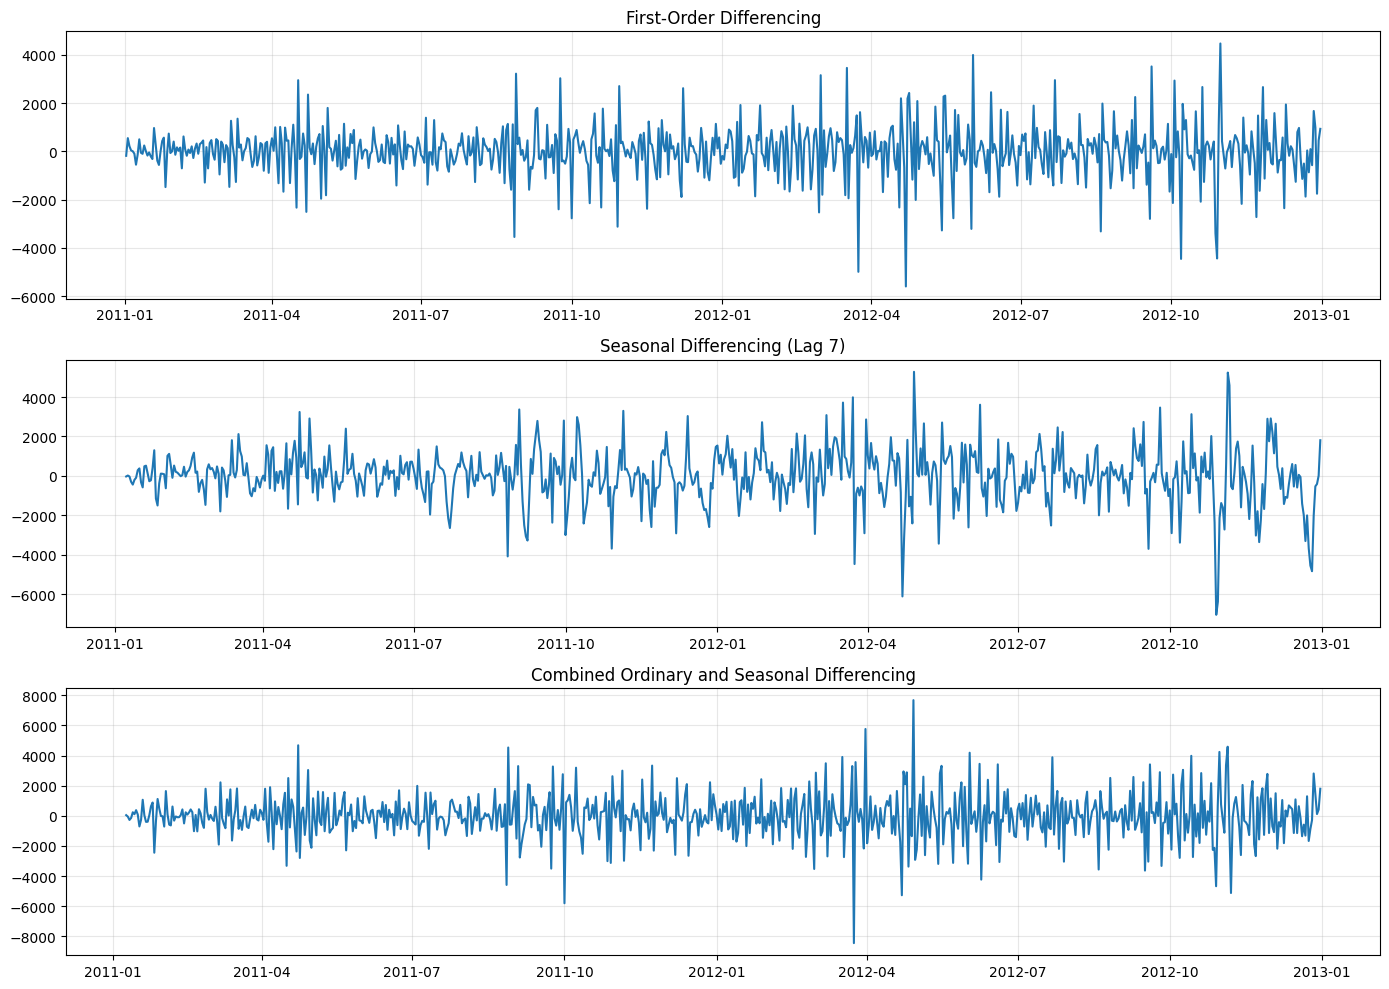

In [87]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(y_diff1)
axes[0].set_title("First-Order Differencing")
axes[0].grid(alpha=0.3)

axes[1].plot(y_diff7)
axes[1].set_title("Seasonal Differencing (Lag 7)")
axes[1].grid(alpha=0.3)

axes[2].plot(y_diff1_diff7)
axes[2].set_title("Combined Ordinary and Seasonal Differencing")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

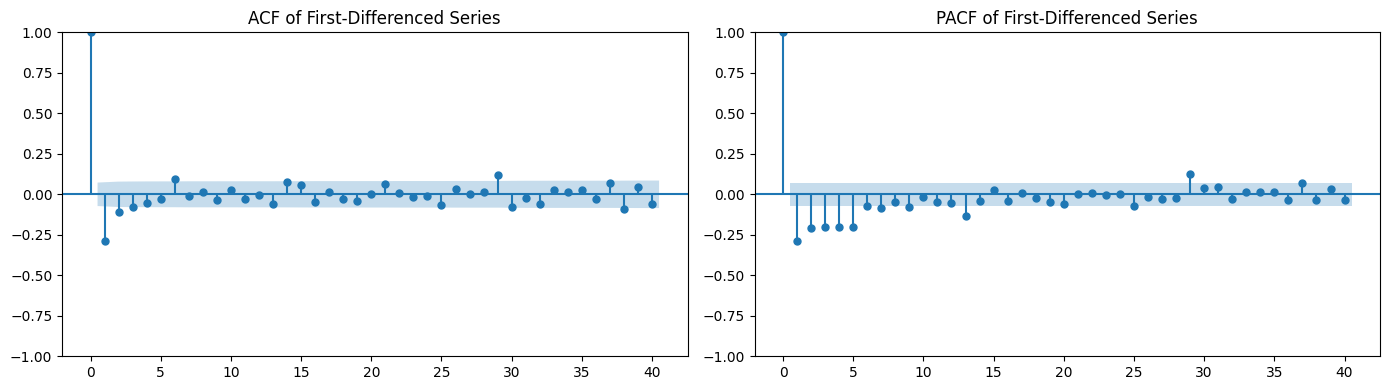

In [88]:
diagnostic_series = y.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(diagnostic_series, lags=40, ax=axes[0])
axes[0].set_title("ACF of First-Differenced Series")

plot_pacf(
    diagnostic_series,
    lags=40,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF of First-Differenced Series")

plt.tight_layout()
plt.show()

In [89]:
split_idx = int(len(y) * 0.80)

train = y.iloc[:split_idx]
test = y.iloc[split_idx:]

print("Training size:", len(train))
print("Testing size:", len(test))

def forecast_metrics(actual, predicted, name):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0
    mape = (
        np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
        if nonzero.any() else np.nan
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


seasonal_naive = np.array([
    train.iloc[-7 + (i % 7)]
    for i in range(len(test))
])

results = [
    forecast_metrics(test, seasonal_naive, "Seasonal Naive (7)")
]

predictions = {
    "Seasonal Naive (7)": seasonal_naive
}

arima_orders = [
    (1, 1, 1),
    (2, 1, 2),
    (1, 0, 1)
]

for order in arima_orders:
    try:
        fitted = ARIMA(train, order=order).fit()

        pred = np.asarray(
            fitted.forecast(steps=len(test))
        )

        name = f"ARIMA{order}"
        predictions[name] = pred
        results.append(forecast_metrics(test, pred, name))

    except Exception as e:
        print(f"ARIMA{order} failed:", e)


sarima_specs = [
    ((1, 1, 1), (1, 1, 1, 7)),
    ((1, 1, 1), (0, 1, 1, 7))
]

for order, seasonal_order in sarima_specs:
    try:
        fitted = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)

        pred = np.asarray(
            fitted.forecast(steps=len(test))
        )

        name = f"SARIMA{order}x{seasonal_order}"
        predictions[name] = pred
        results.append(forecast_metrics(test, pred, name))

    except Exception as e:
        print(f"SARIMA{order}x{seasonal_order} failed:", e)


results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df.round(2))

Training size: 584
Testing size: 147


,Model,MAE,RMSE,MAPE (%)
0,"ARIMA(1, 0, 1)",1269.30,1712.97,231.05
1,"ARIMA(1, 1, 1)",1514.71,2091.37,266.16
2,Seasonal Naive (7),1506.10,2136.77,272.63
3,"ARIMA(2, 1, 2)",1550.73,2162.53,272.56
4,"SARIMA(1, 1, 1)x(0, 1, 1, 7)",2005.77,2820.34,308.64
5,"SARIMA(1, 1, 1)x(1, 1, 1, 7)",2034.39,2858.74,310.01


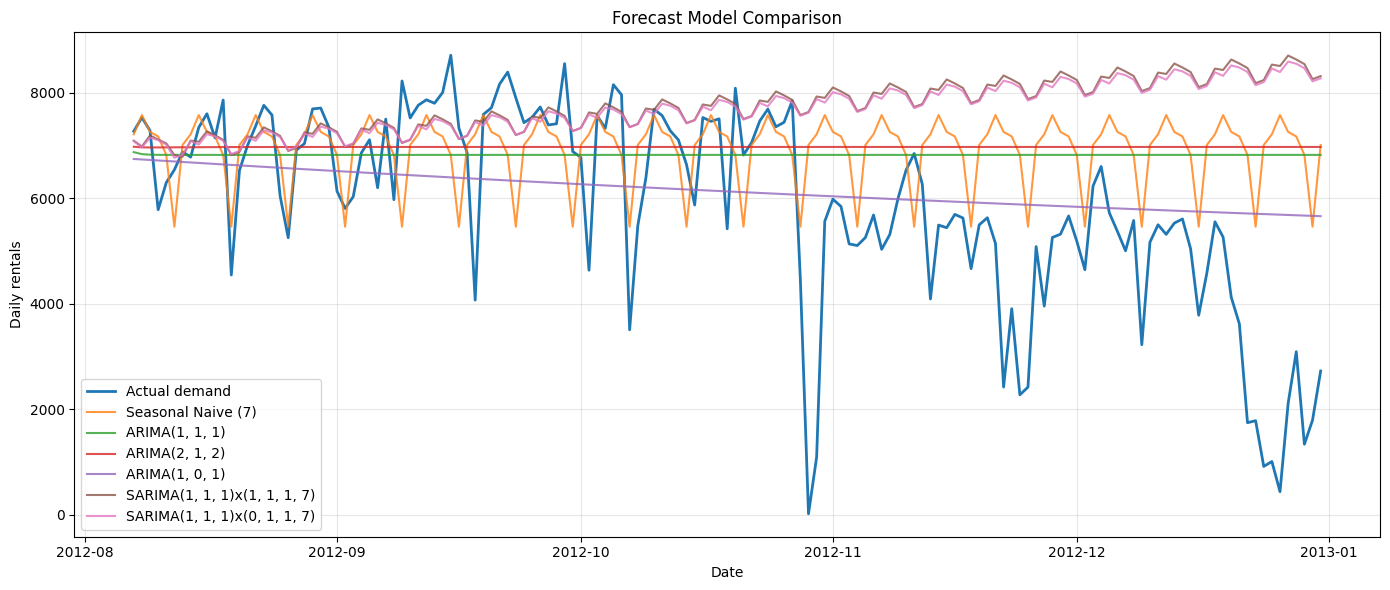

In [90]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual demand",
    linewidth=2
)

for name, pred in predictions.items():
    plt.plot(test.index, pred, label=name, alpha=0.8)

plt.title("Forecast Model Comparison")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Best model by holdout RMSE: ARIMA(1, 0, 1)


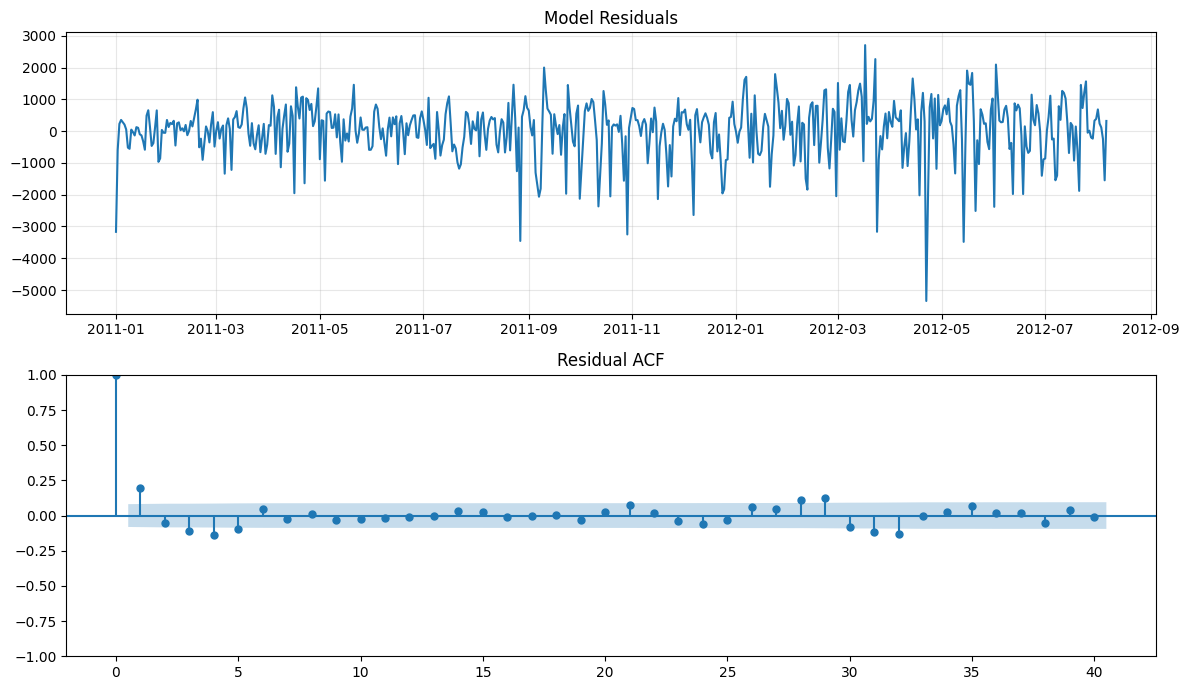

Ljung-Box test:


,lb_stat,lb_pvalue
7,48.971087,2.298741e-08
14,50.823969,4.440964e-06
21,56.078742,4.914169e-05


In [91]:
best_name = results_df.iloc[0]["Model"]
print("Best model by holdout RMSE:", best_name)

if best_name.startswith("ARIMA"):
    order_text = best_name.replace("ARIMA", "")
    order = tuple(map(int, order_text.strip("()").split(",")))

    best_fit = ARIMA(train, order=order).fit()

elif best_name.startswith("SARIMA"):
    # For the two SARIMA candidates defined above
    if "(1, 1, 1)x(1, 1, 1, 7)" in best_name:
        best_fit = SARIMAX(
            train,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)
    else:
        best_fit = SARIMAX(
            train,
            order=(1, 1, 1),
            seasonal_order=(0, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)
else:
    best_fit = None

if best_fit is not None:
    residuals = best_fit.resid

    fig, axes = plt.subplots(2, 1, figsize=(12, 7))

    axes[0].plot(residuals)
    axes[0].set_title("Model Residuals")
    axes[0].grid(alpha=0.3)

    plot_acf(residuals.dropna(), lags=40, ax=axes[1])
    axes[1].set_title("Residual ACF")

    plt.tight_layout()
    plt.show()

    lb = acorr_ljungbox(
        residuals.dropna(),
        lags=[7, 14, 21],
        return_df=True
    )

    print("Ljung-Box test:")
    display(lb)

,Date,Forecast_Demand,Lower_95,Upper_95
0,2013-01-01,2229.4,342.4,4116.3
1,2013-01-02,2260.4,285.1,4235.8
2,2013-01-03,2291.1,233.3,4348.8
3,2013-01-04,2321.3,186.5,4456.2
4,2013-01-05,2351.1,143.8,4558.4
5,2013-01-06,2380.5,105.0,4656.1
6,2013-01-07,2409.5,69.5,4749.6
7,2013-01-08,2438.2,37.0,4839.3
8,2013-01-09,2466.4,7.3,4925.5
9,2013-01-10,2494.2,0.0,5008.4


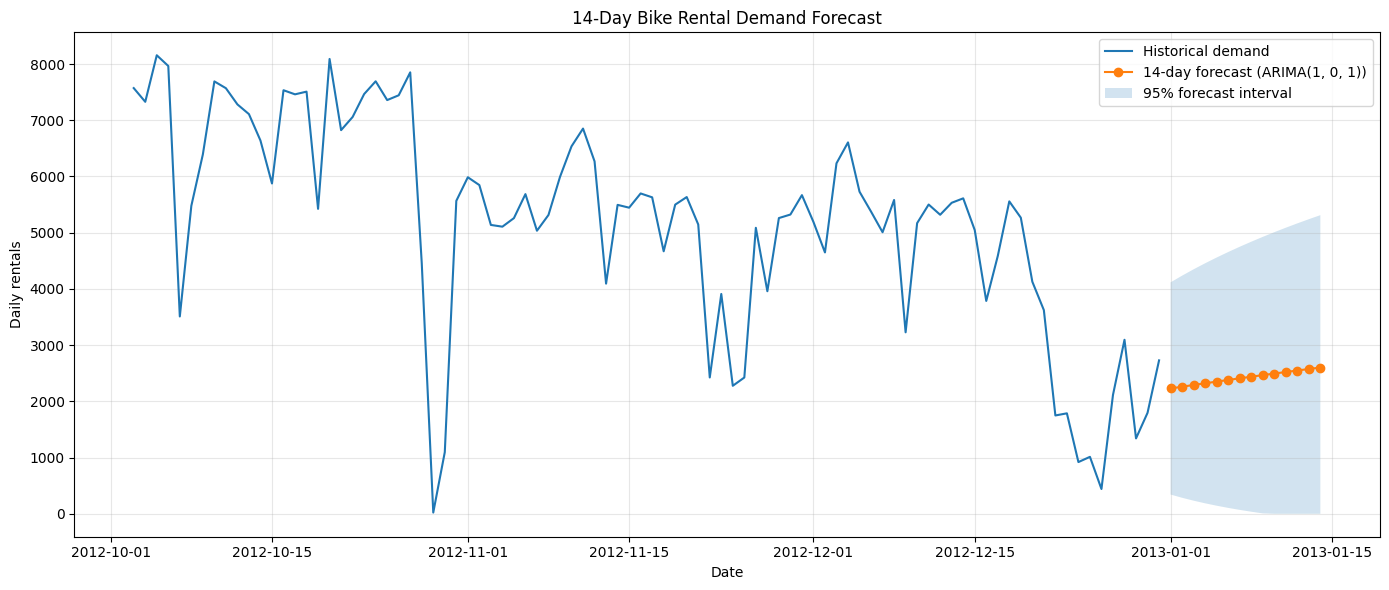

In [92]:
future_dates = pd.date_range(
    start=y.index[-1] + pd.Timedelta(days=1),
    periods=14,
    freq="D"
)

if best_name.startswith("ARIMA"):
    order_text = best_name.replace("ARIMA", "")
    order = tuple(map(int, order_text.strip("()").split(",")))

    final_fit = ARIMA(y, order=order).fit()

    forecast_obj = final_fit.get_forecast(steps=14)

elif best_name.startswith("SARIMA"):
    if "(1, 1, 1)x(1, 1, 1, 7)" in best_name:
        seasonal_order = (1, 1, 1, 7)
    else:
        seasonal_order = (0, 1, 1, 7)

    final_fit = SARIMAX(
        y,
        order=(1, 1, 1),
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False, maxiter=200)

    forecast_obj = final_fit.get_forecast(steps=14)

else:
    # If the seasonal-naive benchmark wins, use it for the future forecast.
    future_mean = np.array([
        y.iloc[-7 + (i % 7)]
        for i in range(14)
    ])

    forecast_df = pd.DataFrame({
        "Date": future_dates,
        "Forecast_Demand": np.maximum(0, future_mean)
    })

    display(forecast_df.round(1))
    forecast_obj = None


if forecast_obj is not None:
    forecast_mean = np.asarray(forecast_obj.predicted_mean)
    forecast_ci = np.asarray(forecast_obj.conf_int())

    forecast_df = pd.DataFrame({
        "Date": future_dates,
        "Forecast_Demand": np.maximum(0, forecast_mean),
        "Lower_95": np.maximum(0, forecast_ci[:, 0]),
        "Upper_95": np.maximum(0, forecast_ci[:, 1])
    })

    display(forecast_df.round(1))


plt.figure(figsize=(14, 6))

plt.plot(
    y.index[-90:],
    y.iloc[-90:],
    label="Historical demand"
)

plt.plot(
    future_dates,
    forecast_df["Forecast_Demand"],
    marker="o",
    label=f"14-day forecast ({best_name})"
)

if "Lower_95" in forecast_df.columns:
    plt.fill_between(
        future_dates,
        forecast_df["Lower_95"],
        forecast_df["Upper_95"],
        alpha=0.2,
        label="95% forecast interval"
    )

plt.title("14-Day Bike Rental Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
latest_7 = y.tail(7).mean()
previous_7 = y.iloc[-14:-7].mean()

change_pct = (
    (latest_7 - previous_7) / previous_7 * 100
    if previous_7 != 0 else np.nan
)

print(f"Previous 7-day average: {previous_7:.1f}")
print(f"Latest 7-day average: {latest_7:.1f}")
print(f"Percentage change: {change_pct:.2f}%")

forecast_next_7 = forecast_df["Forecast_Demand"].head(7).mean()
print(f"Average forecast demand over next 7 days: {forecast_next_7:.1f}")

if latest_7 > previous_7 * 1.05:
    print("\nDemand direction: Increasing")
    print("- Review bicycle availability before likely peaks.")
    print("- Consider additional staff coverage.")
    print("- Review redistribution needs using station-level data.")

elif latest_7 < previous_7 * 0.95:
    print("\nDemand direction: Decreasing")
    print("- Review staffing requirements.")
    print("- Consider maintenance and servicing.")
    print("- Avoid unnecessary redistribution.")

else:
    print("\nDemand direction: Relatively stable")
    print("- Maintain baseline bicycle availability.")
    print("- Use normal staffing as a starting point.")
    print("- Continue monitoring forecasts and uncertainty.")

Previous 7-day average: 3290.1
Latest 7-day average: 1789.9
Percentage change: -45.60%
Average forecast demand over next 7 days: 2320.5

Demand direction: Decreasing
- Review staffing requirements.
- Consider maintenance and servicing.
- Avoid unnecessary redistribution.


In [95]:
latest_7_avg = y.tail(7).mean()
previous_7_avg = y.iloc[-14:-7].mean()

change_pct = (
    (latest_7_avg - previous_7_avg) / previous_7_avg * 100
    if previous_7_avg != 0 else np.nan
)

print(f"Previous 7-day average: {previous_7_avg:.2f}")
print(f"Latest 7-day average: {latest_7_avg:.2f}")
print(f"Percentage change: {change_pct:.2f}%")

if latest_7_avg > previous_7_avg * 1.05:

    print("\nDemand Direction: INCREASING")
    print("- Review bicycle availability before expected demand peaks.")
    print("- Consider additional staff during busy periods.")
    print("- Assess whether redistribution is needed.")

elif latest_7_avg < previous_7_avg * 0.95:

    print("\nDemand Direction: DECREASING")
    print("- Review staffing requirements.")
    print("- Consider maintenance and servicing.")
    print("- Avoid unnecessary redistribution.")

else:

    print("\nDemand Direction: RELATIVELY STABLE")
    print("- Maintain baseline bicycle availability.")
    print("- Use standard staffing as a starting point.")
    print("- Continue monitoring the moving average and forecasts.")

Previous 7-day average: 3290.14
Latest 7-day average: 1789.86
Percentage change: -45.60%

Demand Direction: DECREASING
- Review staffing requirements.
- Consider maintenance and servicing.
- Avoid unnecessary redistribution.
